"""
================================================================================
PIPELINE GEOESPACIAL — SAN MIGUEL DE TUCUMÁN
================================================================================
Autor:      Santiago rodriguez garay
Fecha:      22/09.26
Licencia:   MIT (código) / CC-BY 4.0 (datos)

DESCRIPCIÓN
-----------
Pipeline end-to-end para procesar y visualizar datos geoespaciales del
municipio de San Miguel de Tucumán a partir de dos archivos GeoJSON de
entrada (distritos y barrios).

El pipeline:
    1. Carga las capas de entrada (distritos y barrios).
    2. Genera un límite municipal consolidado por unión topológica de los
       20 distritos, cerrando gaps submétricos mediante buffer/unbuffer en
       proyección UTM (para evitar distorsiones del CRS geográfico).
    3. Produce mapas estáticos (Matplotlib) y un visor interactivo (Folium).
    4. Exporta todos los entregables a disco.

REQUISITOS
----------
    pip install geopandas shapely matplotlib folium branca

ENTRADAS
--------
    - distritos.geojson   (20 polígonos, columnas: DISTRITO, ID DISTRIT)
    - barrios.geojson     (354 polígonos, columnas: BARRIOS, ID BARRIO)

SALIDAS
-------
    - limite_smt_final.geojson
    - mapa_limite_distritos.png
    - mapa_limite_barrios.png
    - mapa_interactivo.html
================================================================================
"""


# SECCIÓN 0 — INSTALACIÓN DE DEPENDENCIAS

In [27]:
# ==============================================================================
# SECCIÓN 0 — INSTALACIÓN DE DEPENDENCIAS
# ==============================================================================
# En Google Colab, las librerías geoespaciales no vienen preinstaladas.
# Ejecutamos pip install con -q (quiet) para no saturar la salida.
# ==============================================================================

!pip install -q geopandas shapely matplotlib folium branca

# SECCIÓN 1 — IMPORTS Y CONFIGURACIÓN

In [28]:
# ==============================================================================
# SECCIÓN 1 — IMPORTS Y CONFIGURACIÓN
# ==============================================================================
# Centralizamos acá todas las rutas y constantes del proyecto. Si el usuario
# mueve los archivos de lugar, solo tiene que actualizar estas variables.
# ==============================================================================

import os
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium import FeatureGroup, LayerControl
import branca.colormap as cm
from shapely.ops import unary_union

# Ignoramos warnings de tipo UserWarning relacionados con geometrías y CRS.
# Los estamos manejando explícitamente, así que no necesitamos verlos.
warnings.filterwarnings('ignore', category=UserWarning)

# ------------------------------------------------------------------------------
# RUTAS DE TRABAJO
# ------------------------------------------------------------------------------
# Directorio base donde están los archivos de entrada. En Colab suele ser
# '/content', pero permitimos override por variable de entorno.
BASE_DIR = Path(os.getenv('SMT_BASE_DIR', '/content'))

ARCHIVO_DISTRITOS = BASE_DIR / 'distritos.geojson'
ARCHIVO_BARRIOS   = BASE_DIR / 'barrios.geojson'
ARCHIVO_LIMITE    = BASE_DIR / 'limite_smt_final.geojson'

SALIDA_MAPA_DISTRITOS = BASE_DIR / 'mapa_limite_distritos.png'
SALIDA_MAPA_BARRIOS   = BASE_DIR / 'mapa_limite_barrios.png'
SALIDA_MAPA_HTML      = BASE_DIR / 'mapa_interactivo.html'

# ------------------------------------------------------------------------------
# PARÁMETROS DEL ALGORITMO DE LIMPIEZA TOPOLÓGICA
# ------------------------------------------------------------------------------
# CRS_UTM: proyección métrica para Tucumán (UTM zona 20S).
# BUFFER_M: ancho en metros para cerrar gaps entre distritos.
#           30 m es seguro para gaps submétricos y no infla el área final
#           más de un 0.2%. Ajustar si el diagnóstico lo requiere.
CRS_UTM  = 'EPSG:32720'
BUFFER_M = 30

# Verificamos que existan los archivos de entrada antes de continuar
for ruta in (ARCHIVO_DISTRITOS, ARCHIVO_BARRIOS):
    if not ruta.exists():
        raise FileNotFoundError(f"No se encontró el archivo requerido: {ruta}")

print("✅ Configuración cargada correctamente")
print(f"   Directorio base: {BASE_DIR}")
print(f"   CRS proyectado:  {CRS_UTM}")
print(f"   Buffer (m):      {BUFFER_M}")

✅ Configuración cargada correctamente
   Directorio base: /content
   CRS proyectado:  EPSG:32720
   Buffer (m):      30


# SECCIÓN 2 — CARGA DE CAPAS DE ENTRADA

In [29]:
# ==============================================================================
# SECCIÓN 2 — CARGA DE CAPAS DE ENTRADA
# ==============================================================================
# Leemos los dos GeoJSON con GeoPandas. La función read_file detecta
# automáticamente el CRS y crea un GeoDataFrame con la geometría activa.
# ==============================================================================

# ------------------------------------------------------------------------------
# 2.1 — Distritos (20 features)
# ------------------------------------------------------------------------------
distritos = gpd.read_file(ARCHIVO_DISTRITOS)

# ------------------------------------------------------------------------------
# 2.2 — Barrios (354 features)
# ------------------------------------------------------------------------------
barrios = gpd.read_file(ARCHIVO_BARRIOS)

# ------------------------------------------------------------------------------
# 2.3 — Resumen de lo cargado
# ------------------------------------------------------------------------------
print("=" * 70)
print("RESUMEN DE CAPAS DE ENTRADA")
print("=" * 70)
print(f"\n📁 distritos.geojson")
print(f"   Features:        {len(distritos)}")
print(f"   CRS:             {distritos.crs}")
print(f"   Geometrías:      {distritos.geometry.geom_type.unique().tolist()}")
print(f"   Columnas:        {list(distritos.columns)}")
print(f"   Nombres únicos:  {distritos['DISTRITO'].nunique()}")

print(f"\n📁 barrios.geojson")
print(f"   Features:        {len(barrios)}")
print(f"   CRS:             {barrios.crs}")
print(f"   Geometrías:      {barrios.geometry.geom_type.unique().tolist()}")
print(f"   Columnas:        {list(barrios.columns)}")

# Verificamos que ambos archivos estén en WGS84 (EPSG:4326). Es el estándar
# para GeoJSON y lo asumimos para el resto del pipeline.
assert distritos.crs.to_epsg() == 4326, "Distritos debe estar en EPSG:4326"
assert barrios.crs.to_epsg() == 4326,   "Barrios debe estar en EPSG:4326"
print("\n✅ Ambas capas en EPSG:4326")

RESUMEN DE CAPAS DE ENTRADA

📁 distritos.geojson
   Features:        20
   CRS:             EPSG:4326
   Geometrías:      ['MultiPolygon']
   Columnas:        ['DISTRITO', 'ID DISTRIT', 'geometry']
   Nombres únicos:  20

📁 barrios.geojson
   Features:        354
   CRS:             EPSG:4326
   Geometrías:      ['MultiPolygon']
   Columnas:        ['BARRIOS', 'ID BARRIO', 'geometry']

✅ Ambas capas en EPSG:4326


# SECCIÓN 3 — GENERACIÓN DEL LÍMITE MUNICIPAL

In [ ]:
# ==============================================================================
# SECCIÓN 3 — GENERACIÓN DEL LÍMITE MUNICIPAL
# ==============================================================================
# El objetivo es obtener UN solo polígono que represente el contorno del
# ejido municipal. Estrategia:
#
#   1) Unir todos los distritos con unary_union.
#      Esto fusiona las geometrías en una sola, pero NO cierra los gaps
#      submétricos que existen entre distritos digitalizados por separado.
#
#   2) Aplicar buffer(+B) y luego buffer(-B) en proyección UTM.
#      El buffer positivo "engorda" los polígonos tapando los gaps. El
#      buffer negativo los devuelve a su tamaño original. El resultado es
#      una geometría limpia sin costuras internas.
#      Se hace en UTM para que B sea una distancia REAL en metros, no grados.
#
#   3) Quedarse con el polígono principal si la unión devuelve un
#      MultiPolygon (islas o fragmentos sueltos).
# ==============================================================================

# ------------------------------------------------------------------------------
# 3.1 — Diagnóstico previo: cuantificar los gaps
# ------------------------------------------------------------------------------
# Comparamos la suma de áreas individuales con el área de la unión. La
# diferencia es el área "perdida" en los gaps entre distritos. Si es 0,
# no hace falta buffer.
# ------------------------------------------------------------------------------

distritos_utm = distritos.to_crs(CRS_UTM)   # Reproyectar a metros

area_suma   = distritos_utm.geometry.area.sum() / 1e6                    # km²
area_union  = unary_union(distritos_utm.geometry).area / 1e6             # km²
gap_total   = area_suma - area_union                                     # km²

print("=" * 70)
print("DIAGNÓSTICO TOPOLÓGICO")
print("=" * 70)
print(f"Suma de áreas individuales:  {area_suma:.4f} km²")
print(f"Área de la unión:            {area_union:.4f} km²")
print(f"Gap total (a cerrar):        {gap_total:.4f} km² "
      f"({gap_total/area_suma*100:.4f}% del área)")

# ------------------------------------------------------------------------------
# 3.2 — Cerrar gaps: buffer positivo + buffer negativo
# ------------------------------------------------------------------------------

# Buffer positivo: expande cada distrito BUFFER_M metros, cubriendo los gaps
distritos_buff = distritos_utm.copy()
distritos_buff['geometry'] = distritos_buff.geometry.buffer(BUFFER_M)

# Unión topológica de los distritos ya expandidos
geo_unida = unary_union(distritos_buff.geometry)

# Buffer negativo: reduce la geometría unida de vuelta a su tamaño real
geo_limpia = geo_unida.buffer(-BUFFER_M)

# ------------------------------------------------------------------------------
# 3.3 — Si la unión devuelve MultiPolygon, quedarse con el polígono principal
# ------------------------------------------------------------------------------
# A veces quedan islas diminutas (por ejemplo, un distrito separado del
# resto). Nos quedamos solo con el polígono más grande, que representa
# el "continente" del municipio.
# ------------------------------------------------------------------------------

if geo_limpia.geom_type == 'MultiPolygon':
    poligonos = sorted(geo_limpia.geoms, key=lambda p: p.area, reverse=True)
    print(f"\n⚠️  Se obtuvieron {len(poligonos)} polígonos. "
          f"Conservando el principal ({poligonos[0].area/1e6:.4f} km²).")
    for i, p in enumerate(poligonos[1:6], start=2):
        print(f"   Descartando fragmento {i}: {p.area/1e6:.6f} km²")
    geo_limpia = poligonos[0]

# ------------------------------------------------------------------------------
# 3.4 — Construir el GeoDataFrame final y volver a WGS84
# ------------------------------------------------------------------------------
limite = gpd.GeoDataFrame(
    {'name': ['San Miguel de Tucumán']},
    geometry=[geo_limpia],
    crs=CRS_UTM
).to_crs('EPSG:4326')   # Volver a WGS84 para exportar como GeoJSON estándar

# ------------------------------------------------------------------------------
# 3.5 — Verificación y guardado
# ------------------------------------------------------------------------------
area_final   = limite.to_crs(CRS_UTM).area.iloc[0] / 1e6
perimetro_km = limite.to_crs(CRS_UTM).geometry.length.iloc[0] / 1000
desviacion   = area_final - area_suma

print("\n" + "=" * 70)
print("LÍMITE MUNICIPAL GENERADO")
print("=" * 70)
print(f"Tipo de geometría:        {limite.geometry.geom_type.iloc[0]}")
print(f"CRS:                      {limite.crs}")
print(f"Área final:               {area_final:.4f} km²")
print(f"Perímetro:                {perimetro_km:.2f} km")
print(f"Geometría válida:         {limite.geometry.is_valid.iloc[0]}")
print(f"Geometría simple:         {limite.geometry.is_simple.iloc[0]}")
print(f"Desviación vs referencia: {desviacion:+.4f} km² "
      f"({desviacion/area_suma*100:+.3f}%)")

# Guardar en disco
limite.to_file(ARCHIVO_LIMITE, driver='GeoJSON')
print(f"\n✅ Guardado: {ARCHIVO_LIMITE.name}")

# SECCIÓN 4 — MAPAS ESTÁTICOS (Matplotlib)

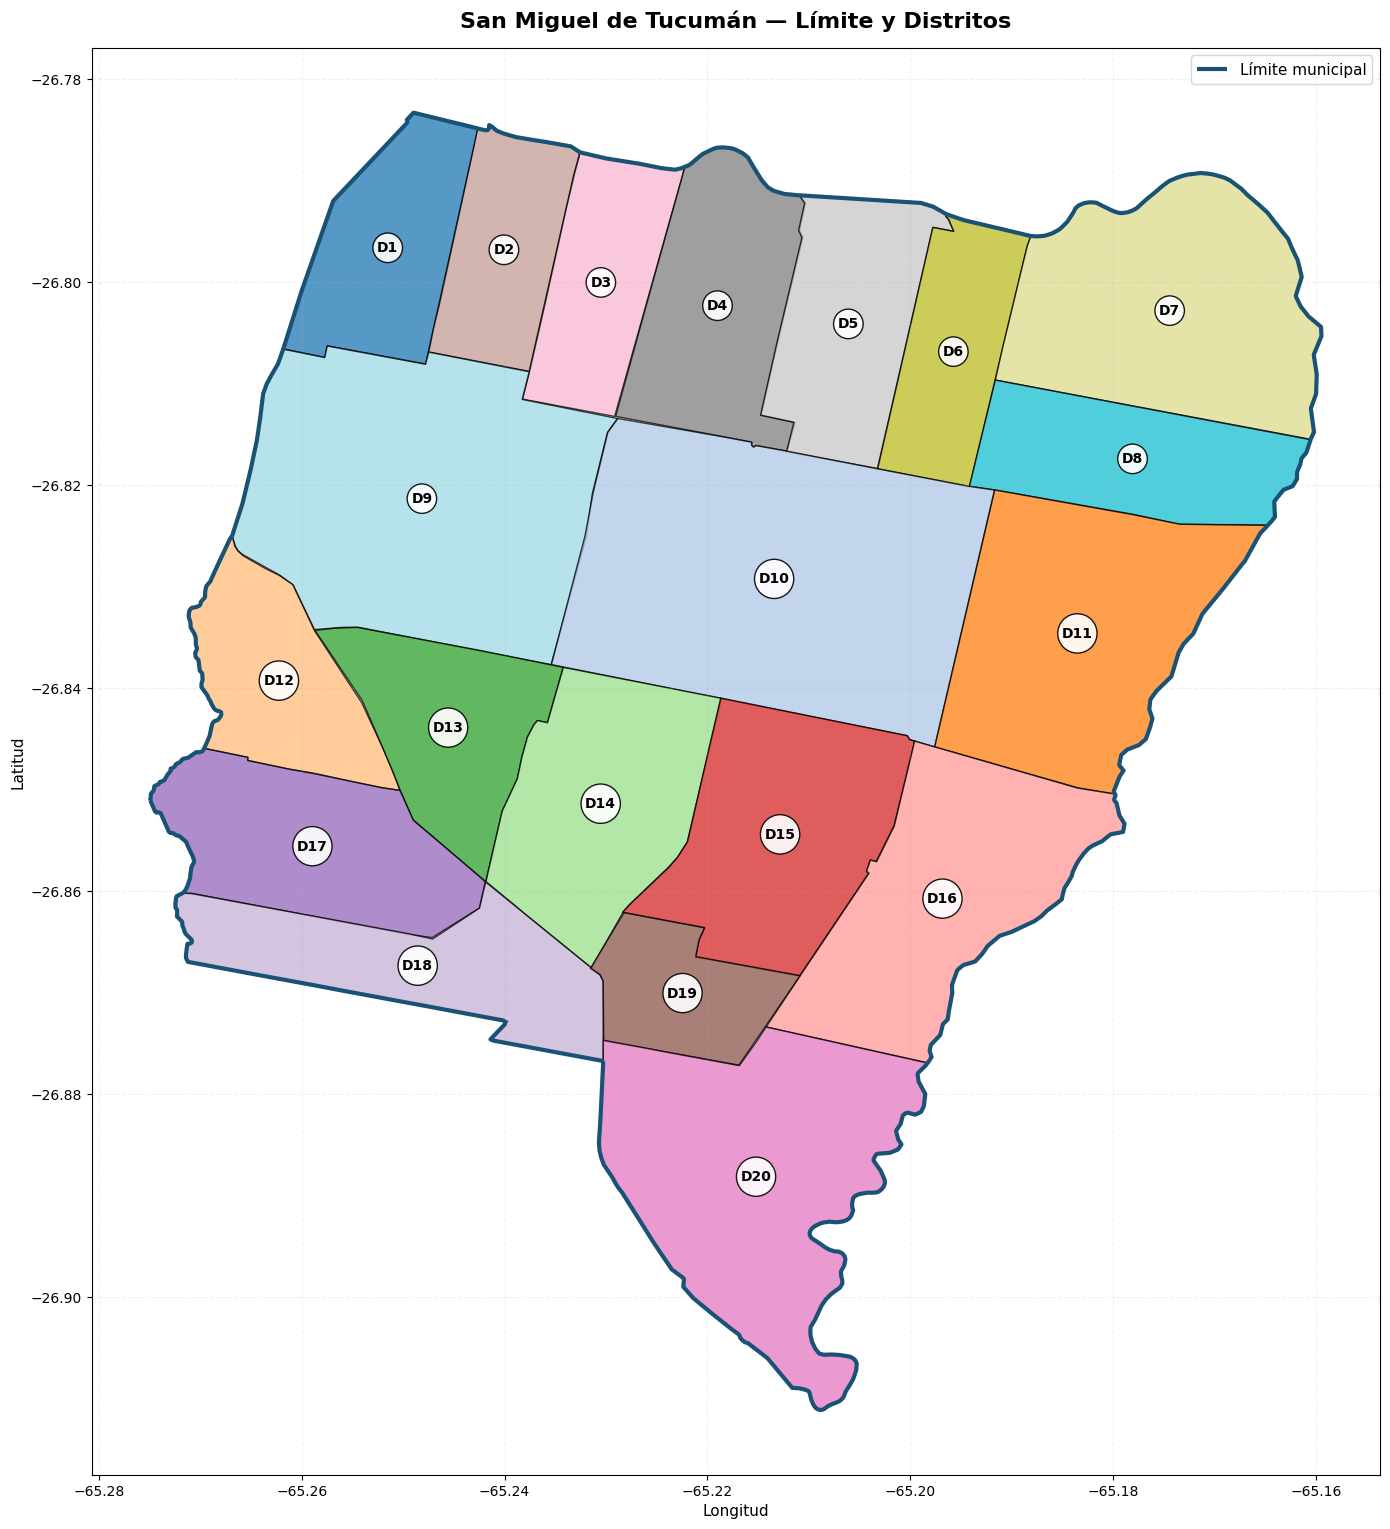

✅ Guardado: mapa_limite_distritos.png


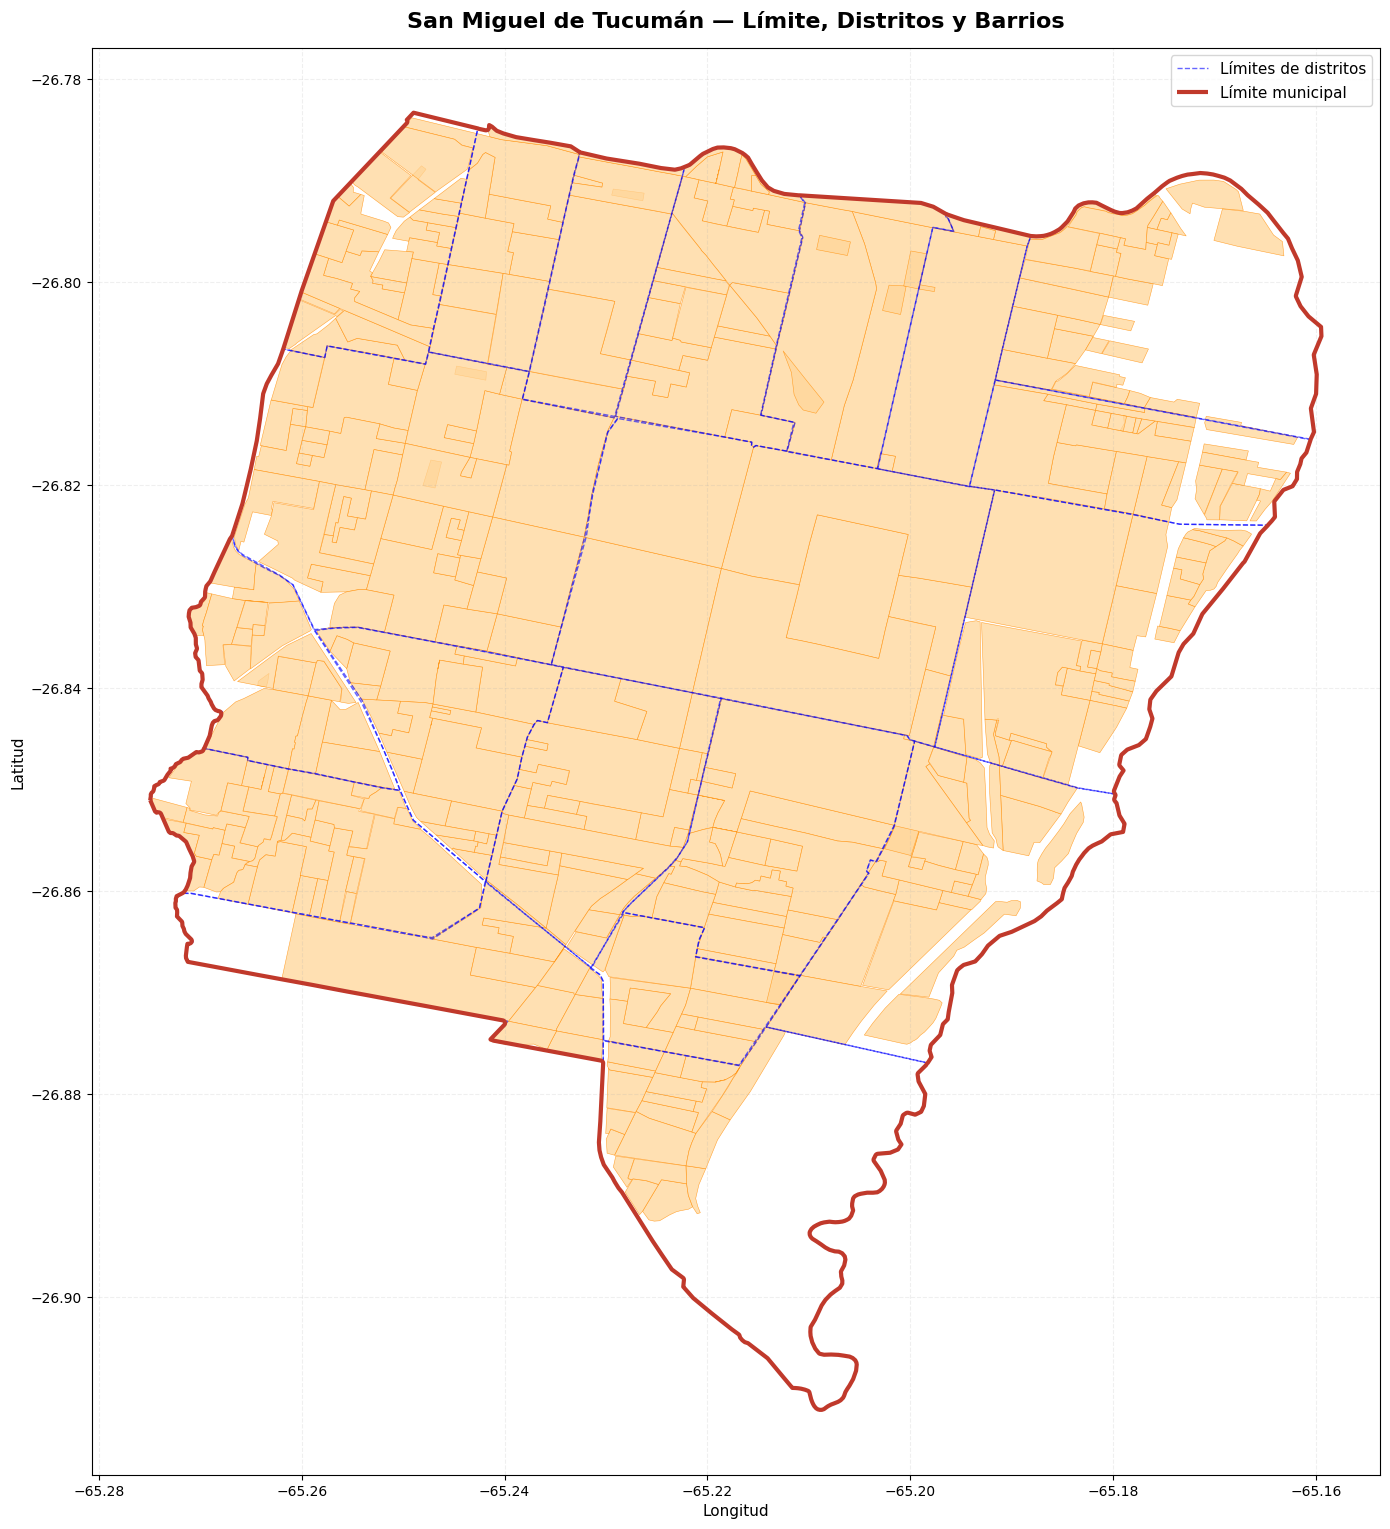

✅ Guardado: mapa_limite_barrios.png


In [30]:
# ==============================================================================
# SECCIÓN 4 — MAPAS ESTÁTICOS (Matplotlib)
# ==============================================================================
# Generamos dos mapas complementarios:
#   - Mapa A: Límite municipal + los 20 distritos coloreados
#   - Mapa B: Límite municipal + los 354 barrios en contorno
# Ambos guardados como PNG de alta resolución.
# ==============================================================================

# ------------------------------------------------------------------------------
# 4.1 — Mapa A: Límite + Distritos
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 16))

# Capa 1: los distritos, coloreados por su identificador único.
# Usamos tab20 (20 colores categóricos) porque tenemos exactamente 20 distritos.
distritos.plot(
    ax=ax,
    column='DISTRITO',
    cmap='tab20',
    edgecolor='black',
    linewidth=1.0,
    alpha=0.75,
    zorder=1
)

# Capa 2: el límite municipal encima, sin relleno, para resaltar el contorno.
limite.boundary.plot(
    ax=ax,
    color='#1a5276',
    linewidth=3,
    zorder=3,
    label='Límite municipal'
)

# Etiquetas: ponemos el nombre corto de cada distrito en su centroide.
# 'DISTRITO 5' → 'D5' para que no sature el mapa.
for _, row in distritos.iterrows():
    centroide = row.geometry.centroid
    etiqueta = row['DISTRITO'].replace('DISTRITO ', 'D')
    ax.annotate(
        etiqueta,
        xy=(centroide.x, centroide.y),
        fontsize=10,
        fontweight='bold',
        ha='center', va='center',
        bbox=dict(boxstyle='circle,pad=0.3', facecolor='white',
                  edgecolor='black', alpha=0.9, linewidth=1),
        zorder=4
    )

ax.set_title('San Miguel de Tucumán — Límite y Distritos',
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Longitud', fontsize=11)
ax.set_ylabel('Latitud', fontsize=11)
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.2)
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig(SALIDA_MAPA_DISTRITOS, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Guardado: {SALIDA_MAPA_DISTRITOS.name}")


# ------------------------------------------------------------------------------
# 4.2 — Mapa B: Límite + Barrios
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 16))

# Capa 1: los barrios en naranja suave. Como son 354, usamos un relleno
# semitransparente para que se distingan los contornos sin saturar.
barrios.plot(
    ax=ax,
    facecolor='#ffd699',
    edgecolor='darkorange',
    linewidth=0.4,
    alpha=0.75,
    zorder=1
)

# Capa 2: distritos como referencia interna (solo borde punteado).
distritos.boundary.plot(
    ax=ax,
    color='blue',
    linewidth=1.0,
    linestyle='--',
    alpha=0.6,
    zorder=2,
    label='Límites de distritos'
)

# Capa 3: límite municipal encima, con color fuerte.
limite.boundary.plot(
    ax=ax,
    color='#c0392b',
    linewidth=3,
    zorder=3,
    label='Límite municipal'
)

ax.set_title(f'San Miguel de Tucumán — Límite, Distritos y Barrios',
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Longitud', fontsize=11)
ax.set_ylabel('Latitud', fontsize=11)
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.2)
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig(SALIDA_MAPA_BARRIOS, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Guardado: {SALIDA_MAPA_BARRIOS.name}")

# SECCIÓN 5 — MAPA INTERACTIVO CON FOLIUM

In [31]:
# ==============================================================================
# SECCIÓN 5 — MAPA INTERACTIVO CON FOLIUM
# ==============================================================================
# Generamos un mapa HTML autónomo con:
#   - 4 mapas base intercambiables (2 cartográficos + 1 satelital + 1 oscuro)
#   - 3 capas de datos: límite, distritos, barrios (toggables)
#   - Tooltips al pasar el mouse con información de cada capa
#   - Leyenda de colores para los distritos
#   - Título flotante
#
# El resultado es un archivo .html que se puede abrir en cualquier navegador
# sin necesidad de tener Python instalado.
# ==============================================================================

# ------------------------------------------------------------------------------
# 5.1 — Crear mapa base y centrarlo en el centroide del límite
# ------------------------------------------------------------------------------
centro = [
    limite.geometry.centroid.y.iloc[0],   # latitud
    limite.geometry.centroid.x.iloc[0]    # longitud
]

m = folium.Map(
    location=centro,
    zoom_start=12,
    tiles=None,              # No agregamos tiles por defecto; los definimos abajo
    control_scale=True,      # Muestra la barra de escala
    prefer_canvas=True       # Usa canvas HTML5 (mejor rendimiento con muchas features)
)

# ------------------------------------------------------------------------------
# 5.2 — Mapas base (el usuario los cambia desde el control de capas)
# ------------------------------------------------------------------------------
# CartoDB Positron: cartográfico claro, muy legible para superponer datos.
folium.TileLayer(
    'CartoDB positron',
    name='🗺️ Cartográfico (claro)',
    control=True
).add_to(m)

# CartoDB Dark Matter: cartográfico oscuro, ideal para resaltar colores vivos.
folium.TileLayer(
    'CartoDB dark_matter',
    name='🌙 Cartográfico (oscuro)',
    control=True
).add_to(m)

# Esri World Imagery: imagen satelital de alta resolución.
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/'
          'World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri, Maxar, Earthstar Geographics',
    name='🛰️ Satelital (Esri)',
    control=True
).add_to(m)

# OpenStreetMap: mapa colaborativo estándar.
folium.TileLayer(
    'OpenStreetMap',
    name='🛣️ OpenStreetMap',
    control=True
).add_to(m)

# ------------------------------------------------------------------------------
# 5.3 — Capa 1: Límite municipal
# ------------------------------------------------------------------------------
grupo_limite = FeatureGroup(name='🔴 Límite Municipal', show=True)

folium.GeoJson(
    limite.__geo_interface__,
    style_function=lambda x: {
        'fillColor':   '#a8d5e2',
        'color':       '#1a5276',
        'weight':      3,
        'fillOpacity': 0.15,
        'opacity':     1.0
    },
    highlight_function=lambda x: {
        'weight':      5,
        'color':       '#e74c3c',
        'fillOpacity': 0.30
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name'],
        aliases=['Municipio:'],
        style=('background-color: white; color: #1a5276; '
               'font-family: sans-serif; font-size: 13px; '
               'padding: 8px; border-radius: 4px;')
    )
).add_to(grupo_limite)

grupo_limite.add_to(m)

# ------------------------------------------------------------------------------
# 5.4 — Capa 2: Distritos (coloreados individualmente)
# ------------------------------------------------------------------------------
# Asignamos un color único a cada distrito con una paleta categórica de Branca.
# Set1_09 provee 9 colores vivos; los ciclamos para cubrir los 20 distritos.
distritos_ordenados = sorted(distritos['DISTRITO'].unique())
colormap_distritos  = cm.linear.Set1_09.scale(0, len(distritos_ordenados) - 1)
color_por_distrito  = {d: colormap_distritos(i)
                       for i, d in enumerate(distritos_ordenados)}

grupo_distritos = FeatureGroup(name=f'🟠 Distritos ({len(distritos)})', show=True)

folium.GeoJson(
    distritos.__geo_interface__,
    style_function=lambda feat: {
        'fillColor':   color_por_distrito.get(feat['properties']['DISTRITO'],
                                              '#cccccc'),
        'color':       'black',
        'weight':      1.5,
        'fillOpacity': 0.45,
        'opacity':     0.9
    },
    highlight_function=lambda feat: {
        'weight':      3,
        'color':       '#000000',
        'fillOpacity': 0.70
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['DISTRITO', 'ID DISTRIT'],
        aliases=['Distrito:', 'ID:'],
        style=('background-color: white; color: #333; '
               'font-family: sans-serif; font-size: 13px; '
               'padding: 8px; border-radius: 4px; '
               'box-shadow: 2px 2px 6px rgba(0,0,0,0.3);')
    )
).add_to(grupo_distritos)

grupo_distritos.add_to(m)

# ------------------------------------------------------------------------------
# 5.5 — Capa 3: Barrios (solo contornos para no saturar)
# ------------------------------------------------------------------------------
# Con 354 barrios, un relleno sólido saturaría el mapa. Usamos solo el
# contorno y mostramos info al hacer hover.
grupo_barrios = FeatureGroup(name=f'🟡 Barrios ({len(barrios)})', show=False)

folium.GeoJson(
    barrios.__geo_interface__,
    style_function=lambda x: {
        'fillColor':   'transparent',
        'color':       '#e67e22',
        'weight':      0.8,
        'fillOpacity': 0.0,
        'opacity':     0.8
    },
    highlight_function=lambda x: {
        'weight':      2,
        'color':       '#d35400',
        'fillColor':   '#f39c12',
        'fillOpacity': 0.40
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['BARRIOS', 'ID BARRIO'],
        aliases=['Barrio:', 'ID:'],
        style=('background-color: white; color: #333; '
               'font-family: sans-serif; font-size: 12px; '
               'padding: 6px; border-radius: 4px; '
               'box-shadow: 2px 2px 6px rgba(0,0,0,0.3);')
    )
).add_to(grupo_barrios)

grupo_barrios.add_to(m)

# ------------------------------------------------------------------------------
# 5.6 — Leyenda de distritos (HTML flotante, abajo a la izquierda)
# ------------------------------------------------------------------------------
leyenda = (
    '<div style="position: fixed; bottom: 30px; left: 30px; '
    'width: 220px; max-height: 400px; overflow-y: auto; '
    'background-color: white; border: 2px solid #333; border-radius: 6px; '
    'padding: 10px; z-index: 9999; font-family: sans-serif; font-size: 11px; '
    'box-shadow: 2px 2px 8px rgba(0,0,0,0.3);">'
    '<b style="font-size: 12px;">Distritos</b>'
    '<hr style="margin: 5px 0;">'
)

for d in distritos_ordenados:
    color = color_por_distrito[d]
    leyenda += (
        f'<div style="margin: 2px 0;">'
        f'<span style="display:inline-block; width:12px; height:12px; '
        f'background:{color}; border:1px solid #333; '
        f'vertical-align:middle; margin-right:5px;"></span>'
        f'{d}</div>'
    )

leyenda += '</div>'
m.get_root().html.add_child(folium.Element(leyenda))

# ------------------------------------------------------------------------------
# 5.7 — Título flotante (centrado arriba)
# ------------------------------------------------------------------------------
titulo = (
    '<div style="position: fixed; top: 15px; left: 50%; '
    'transform: translateX(-50%); background-color: white; '
    'padding: 10px 20px; border-radius: 8px; border: 2px solid #1a5276; '
    'z-index: 9999; font-family: sans-serif; font-size: 16px; '
    'font-weight: bold; color: #1a5276; '
    'box-shadow: 2px 2px 8px rgba(0,0,0,0.3);">'
    'San Miguel de Tucumán — Límite, Distritos y Barrios'
    '</div>'
)
m.get_root().html.add_child(folium.Element(titulo))

# ------------------------------------------------------------------------------
# 5.8 — Control de capas (arriba a la derecha, expandido)
# ------------------------------------------------------------------------------
LayerControl(collapsed=False, position='topright').add_to(m)

# Mostrar en el notebook
m

# SECCIÓN 6 — EXPORTAR EL MAPA INTERACTIVO

In [33]:
# ==============================================================================
# SECCIÓN 6 — EXPORTAR EL MAPA INTERACTIVO
# ==============================================================================
# Guardamos el objeto Folium como HTML autónomo. Este archivo incluye todas
# las librerías JS necesarias embebidas (Leaflet + plugins), por lo que se
# puede abrir en cualquier navegador sin conexión a internet ni Python.
# ==============================================================================

m.save(str(SALIDA_MAPA_HTML))
tamaño_kb = SALIDA_MAPA_HTML.stat().st_size / 1024
print(f"✅ Guardado: {SALIDA_MAPA_HTML.name} ({tamaño_kb:.1f} KB)")

# En Colab, descargar automáticamente los archivos generados:
try:
    from google.colab import files
    for salida in (ARCHIVO_LIMITE, SALIDA_MAPA_DISTRITOS,
                   SALIDA_MAPA_BARRIOS, SALIDA_MAPA_HTML):
        files.download(str(salida))
except ImportError:
    # Si no estamos en Colab, los archivos ya están en disco
    print("\n📂 Archivos generados:")
    for salida in (ARCHIVO_LIMITE, SALIDA_MAPA_DISTRITOS,
                   SALIDA_MAPA_BARRIOS, SALIDA_MAPA_HTML):
        print(f"   {salida}")

✅ Guardado: mapa_interactivo.html (421.4 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>